<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/20_fuego/23_fuego_tendencias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 23 · Tendencias del fuego: coberturas quemadas y focos FIRMS (Terra + Aqua frente a Terra)

**Autor:** Jonatan

**Pregunta:** ¿qué coberturas se queman, con qué tasa y hacia dónde van los focos de calor y el área quemada entre 2001 y 2024? ¿La tendencia de los focos se mantiene si se usa Terra + Aqua en lugar de Terra sola?

**Entradas:**
- `datos/comunes/`: `firms_mensual_municipio.csv` (cuaderno 03), `chirps_mensual_municipio.csv` (cuaderno 11) y `oni_mensual.csv` (cuaderno 10).
- `modulos/expansion/datos/procesados/` (DVC): coberturas MapBiomas y EVA, de los scripts `02_unir_mapbiomas.py` y `03_series_y_cruce_eva.py` del módulo de expansión.
- `modulos/fuego_expansion/datos/crudos/` (DVC): área quemada de MapBiomas Fuego y pérdida de vegetación.
- El panel municipio × año se construye en el cuaderno con `scripts/01_preparar_panel.py`, así que no depende de otro cuaderno.

**Salidas:**
- `modulos/fuego_expansion/resultados/tablas/municipal/composicion_quema_por_municipio.csv` y `tendencias_fuego.csv`.
- `modulos/fuego_expansion/resultados/figuras/municipal/02_quema_por_cobertura.png`.

**Método:** composición y tasas de quema por cobertura, prueba de Wilcoxon por municipio y tendencia de Mann-Kendall con pendiente de Sen. Los focos FIRMS se analizan con Terra + Aqua desde 2003 (serie principal) y con Terra sola (sensibilidad).

## Qué coberturas se queman

Este notebook caracteriza el fuego antes de relacionarlo con el cambio agropecuario. Cada cobertura es un grupo de clases de MapBiomas, como se define en el cuaderno 52. Usa dos indicadores que tienen denominadores distintos.

- **Composición de lo quemado.** De toda la superficie quemada en un municipio durante el período, qué porcentaje corresponde a cada clase. Se calcula con las hectáreas acumuladas por clase y las hectáreas quemadas totales.
- **Tasa de quema por cobertura.** Qué porcentaje de la superficie disponible de una clase se quemó en un año. Por ejemplo, 20 % significa 20 hectáreas quemadas por cada 100 hectáreas de esa cobertura.

## 1. Preparar el entorno

Se cargan las herramientas para leer los datos, mostrar las tablas y guardar las figuras en las carpetas del análisis municipal.

In [5]:
import sys
from importlib import import_module
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Rutas del proyecto: funcionan en Colab y en local
import os, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/

def traer(ruta):
    """Baja de DVC una carpeta o un archivo pesado del repo si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

traer('modulos/fuego_expansion/datos/crudos')
traer('modulos/expansion/datos/procesados')
sys.path.insert(0, os.path.join(RAIZ, 'modulos', 'fuego_expansion', 'scripts'))

import config as cfg
from utils import estilo_matplotlib, leer_csv, pie_fuente

derivados = cfg.DERIVADOS / "municipal"
tablas = cfg.TABLAS / "municipal"
figuras = cfg.FIGURAS / "municipal"
for carpeta in (derivados, tablas, figuras):
    carpeta.mkdir(parents=True, exist_ok=True)
estilo_matplotlib()

## 2. Construir el panel y la serie regional

El panel, que se construye aquí con `scripts/01_preparar_panel.py`, permite comparar coberturas dentro de cada municipio y año. La serie regional permite seguir la evolución de las tasas en el conjunto de la Altillanura.

In [6]:
preparar = import_module("01_preparar_panel")
panel = preparar.construir_panel()
regional = preparar.serie_regional(panel)

## 3. Calcular composición, tasas y tendencias

La primera tabla muestra las hectáreas quemadas medias, la composición acumulada y la media de las tasas anuales por municipio. La **razón de tasas** divide la media agropecuaria por la media de formación natural no forestal.

### Wilcoxon por municipio

Se aplica una prueba bilateral de rangos con signo a las **diferencias anuales emparejadas**. Para cada municipio y año con ambas tasas se calcula la tasa agropecuaria menos la natural no forestal. Por ejemplo, 7 % y 25 % dan una diferencia de −18 pp. Los años con algún dato faltante se omiten.

La prueba excluye diferencias iguales a cero, ordena las demás por su valor absoluto y asigna rangos, promediándolos cuando hay empates. Luego compara las sumas de rangos positivos y negativos. La hipótesis nula es que la distribución de las diferencias es simétrica alrededor de cero. El valor *p* evalúa el contraste en ambas direcciones. Para interpretar la dirección se consultan las diferencias y las tasas observadas. La prueba compara tasas de quema entre coberturas. El cambio agropecuario se analiza en el cuaderno 50.

Se hace una prueba por municipio, con hasta 24 pares. Los valores *p* son exploratorios porque la prueba trata los pares de años distintos como independientes y se reportan sin ajuste por las siete comparaciones. Un *p* impreso como 0,000 refleja el redondeo.

### Tendencias

La segunda tabla muestra tendencias regionales. **Tau de Kendall** indica su sentido y la **pendiente de Sen** estima cuánto cambia la serie por año, en hectáreas, puntos porcentuales o focos según el indicador. Sus valores *p* se reportan sin ajuste por dependencia temporal o comparaciones múltiples.

In [7]:
fuego = import_module("04_fuego_por_clase")
composicion = fuego.composicion(panel)
tendencias = fuego.tendencias(panel, regional)
composicion.to_csv(tablas / "composicion_quema_por_municipio.csv", encoding="utf-8-sig")
tendencias.to_csv(tablas / "tendencias_fuego.csv", index=False, encoding="utf-8-sig")
display(composicion)
display(tendencias.query("territorio == 'Altillanura'"))

,mpio_cdpmp,quemado_medio_ha,pct_natural,pct_agro,pct_bosque,pct_sin_vegetacion,tasa_quema_natural_media_pct,tasa_quema_agro_media_pct,razon_tasa_agro_natural,p_wilcoxon_agro_vs_natural
municipio,,,,,,,,,,
Cumaribo,99773,479734.568,97.467,1.512,0.925,0.095,20.844,3.689,0.177,0.0
La Primavera,99524,380941.359,98.274,1.201,0.494,0.031,24.322,5.554,0.228,0.0
Puerto Gaitán,50568,321939.445,89.491,8.900,1.578,0.031,29.474,7.425,0.252,0.0
Puerto Carreño,99001,258281.955,96.251,3.274,0.455,0.021,28.328,10.425,0.368,0.0
Mapiripán,50325,92933.470,89.925,9.021,1.002,0.052,22.820,4.928,0.216,0.0
Santa Rosalía,99624,71544.570,92.489,6.939,0.514,0.057,24.051,10.391,0.432,0.0
Puerto López,50573,43444.209,85.030,14.097,0.872,0.001,14.642,2.049,0.140,0.0


,territorio,mpio_cdpmp,serie,tau,p,pendiente_sen_por_anio
0,Altillanura,NaN,"Focos FIRMS dic-mar (Terra + Aqua, desde 2003)",-0.1775,0.2628,-94.3000
8,Altillanura,NaN,"Focos FIRMS dic-mar (solo Terra, desde 2001)",-0.3188,0.0298,-68.6667
16,Altillanura,NaN,"Focos FIRMS dic-mar (solo Terra, desde 2003)",-0.2468,0.1150,-56.0000
24,Altillanura,NaN,Área quemada total (ha),0.0725,0.6410,9203.5371
32,Altillanura,NaN,Vegetación natural no forestal quemada (ha),0.0507,0.7498,6736.1912
40,Altillanura,NaN,Área agropecuaria quemada (ha),0.5290,0.0002,2845.2904
48,Altillanura,NaN,Tasa de quema natural no forestal (%),0.1232,0.4172,0.2338
56,Altillanura,NaN,Tasa de quema agropecuaria (%),0.1812,0.2269,0.0668


### Lectura de las tablas

- La **formación natural no forestal** concentra entre **85,0 %** de lo quemado en Puerto López y **98,3 %** en La Primavera. Sus tasas medias también son más altas que las agropecuarias en los siete municipios. En Puerto Gaitán, por ejemplo, son **29,5 %** y **7,4 %**, respectivamente.
- La superficie agropecuaria quemada aumenta a un ritmo estimado de **2.845 ha por año** en la región (*p* = 0,0002). El aumento estimado de la **tasa** agropecuaria es de **0,067 pp por año** y resulta incierto (*p* = 0,227). Las hectáreas quemadas pueden aumentar a medida que crece la superficie agropecuaria disponible.
- El área quemada total presenta una tendencia incierta (*p* = 0,641), mientras que los focos FIRMS de la temporada seca (Terra + Aqua, desde 2003) disminuyen en unos **94 focos por año**, con una tendencia incierta (*p* = 0,263). Con Terra sola la disminución es de unos **69 focos por año** desde 2001 (*p* = 0,030) y de **56** desde 2003 (*p* = 0,115). Las pendientes de Terra + Aqua y de Terra no son comparables en magnitud porque la primera cuenta cerca del doble de focos; solo se compara el sentido y si la prueba distingue la tendencia de cero. Los indicadores miden magnitudes distintas y abarcan ventanas diferentes.

## 4. Comparar las tasas y la composición en una figura

El panel izquierdo sigue las tasas regionales por año. El derecho reparte el total quemado de cada municipio entre coberturas. La longitud de cada segmento de la barra expresa un porcentaje del total quemado en ese municipio.

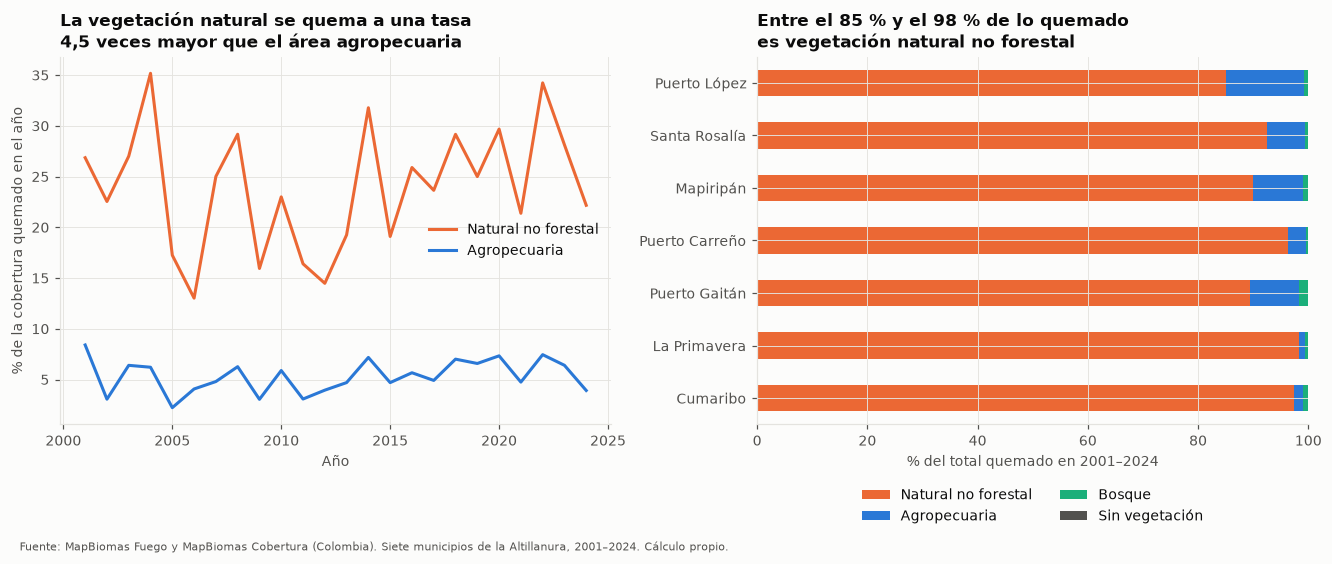

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
regional.plot(x="anio", y=["tasa_quema_natural", "tasa_quema_agro"], ax=ejes[0],
              color=[cfg.COLOR_SABANA, cfg.COLOR_AGRO])
ejes[0].legend(["Natural no forestal", "Agropecuaria"])
razon = f"{regional['tasa_quema_natural'].mean() / regional['tasa_quema_agro'].mean():.1f}".replace(".", ",")
ejes[0].set(title=f"La vegetación natural se quema a una tasa\n{razon} veces mayor que el área agropecuaria",
            xlabel="Año", ylabel="% de la cobertura quemado en el año")
composicion[["pct_natural", "pct_agro", "pct_bosque", "pct_sin_vegetacion"]].plot.barh(
    ax=ejes[1], stacked=True, color=[cfg.COLOR_SABANA, cfg.COLOR_AGRO, cfg.COLOR_BOSQUE, cfg.COLOR_TEXTO_2])
ejes[1].legend(["Natural no forestal", "Agropecuaria", "Bosque", "Sin vegetación"],
               loc="upper center", bbox_to_anchor=(0.5, -0.14), ncols=2)
natural = composicion["pct_natural"]
ejes[1].set(title=f"Entre el {natural.min():.0f} % y el {natural.max():.0f} % de lo quemado\nes vegetación natural no forestal",
            xlabel="% del total quemado en 2001–2024", ylabel="", xlim=(0, 100))
fig.get_layout_engine().set(rect=(0, 0.04, 1, 0.96))
pie_fuente(fig, "Fuente: MapBiomas Fuego y MapBiomas Cobertura (Colombia). Siete municipios de la Altillanura, 2001–2024. Cálculo propio.")
fig.savefig(figuras / "02_quema_por_cobertura.png")
plt.show()

### Lectura de la figura

La línea de vegetación natural no forestal se mantiene por encima de la agropecuaria en toda la serie regional. Sus tasas medias anuales son **24,0 %** y **5,3 %**, respectivamente. Junto con la composición de las barras, esto muestra que la formación natural no forestal concentra la mayor parte de la superficie quemada y que también se quema una fracción mayor de su propia superficie. Para saber si esa quema se asocia con cambios agropecuarios posteriores, el cuaderno 50 incorpora el orden temporal.